# Explaining a classifier

This notebook explains the predictions of a random forest that classifies wines into three cultivars from 13 chemical measurements (the wine dataset bundled with scikit-learn). It shows:

1. the explanation of one prediction: relevant features, decision path and counterfactuals;
2. counterfactuals for a desired class;
3. the counterfactuals of many instances, their selection and their evaluation.

Requirements: `pip install "nife[examples]"`.

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

from nife.counterfactual import TreeCounterfactualExplainer, select_counterfactuals

## Data and model

In [2]:
X, y = load_wine(return_X_y=True, as_frame=True)
model = RandomForestClassifier(random_state=0)
print(f"accuracy (5-fold cross-validation): {cross_val_score(model, X, y).mean():.3f}")
model.fit(X, y)
X.head()

accuracy (5-fold cross-validation): 0.983


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 1. One prediction

`TreeCounterfactualExplainer` explains with a surrogate decision tree. It only needs the model and reference data — usually the training data. `random_state` makes the explanations reproducible.

In [3]:
explainer = TreeCounterfactualExplainer(model, X, random_state=0)
explanation = explainer.explain(X.iloc[0])
explanation

TreeCounterfactualExplanation (classification) of an instance predicted 0
  decision path: color_intensity > 3.437 and proline > 651.7
  relevant features: proline, color_intensity, flavanoids
  crossed rule: proline > 651.7 -> proline <= 651.7
  counterfactuals: 42 (data: 42)
  closest: distance 0.176, 13 changed features, predicted 1
  fidelity: instance agreement True, local fidelity 1.00 (neighborhood: around the instance, scale 1)

The surrogate tree learned the model's behavior around the instance. The features it uses are the relevant features of the prediction:

In [4]:
explanation.feature_importances

proline            0.436622
color_intensity    0.336984
flavanoids         0.226394
dtype: float64

The instance's path in the tree is in green; the other side of the crossed rule, where the counterfactuals lie, is in orange:

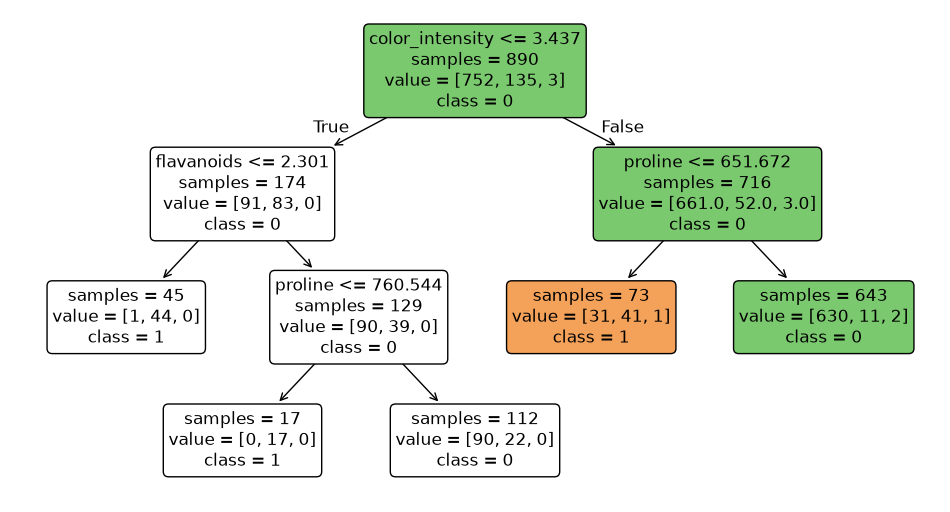

In [5]:
explanation.plot_tree();

The counterfactuals are examples of the data on the other side of the crossed rule that the model assigns to another class, ranked by their (Gower) distance to the instance:

In [6]:
explanation.counterfactuals.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,prediction,source,distance,changed_features
0,13.11,1.01,1.70,15.0,78.0,2.98,3.18,0.26,2.28,5.30,1.12,3.18,502.0,1,data,0.175534,13
1,12.37,1.13,2.16,19.0,87.0,3.50,3.10,0.19,1.87,4.45,1.22,2.87,420.0,1,data,0.231015,13
2,12.43,1.53,2.29,21.5,86.0,2.74,3.15,0.39,1.77,3.94,0.69,2.84,352.0,1,data,0.236841,13
3,12.37,1.17,1.92,19.6,78.0,2.11,2.00,0.27,1.04,4.68,1.12,3.48,510.0,1,data,0.245112,13
4,13.49,1.66,2.24,24.0,87.0,1.88,1.84,0.27,1.03,3.74,0.98,2.78,472.0,1,data,0.247416,13


What the closest counterfactual changes:

In [7]:
closest = explanation.counterfactuals.iloc[0]
comparison = pd.DataFrame({"instance": explanation.instance, "counterfactual": closest[X.columns]})
comparison[comparison["instance"] != comparison["counterfactual"]]

,instance,counterfactual
alcohol,14.23,13.11
malic_acid,1.71,1.01
ash,2.43,1.7
alcalinity_of_ash,15.60,15.0
magnesium,127.00,78.0
total_phenols,2.80,2.98
flavanoids,3.06,3.18
nonflavanoid_phenols,0.28,0.26
proanthocyanins,2.29,2.28
color_intensity,5.64,5.3


## 2. A desired class

By default any other class counts. With `desired`, only counterfactuals of that class:

In [8]:
to_class_2 = explainer.explain(X.iloc[0], desired=2)
to_class_2

TreeCounterfactualExplanation (classification) of an instance predicted 0, desired 2
  decision path: color_intensity > 3.437 and proline > 651.7
  relevant features: proline, color_intensity, flavanoids
  crossed rule: proline > 651.7 -> proline <= 651.7
  counterfactuals: 29 (data: 29)
  closest: distance 0.284, 13 changed features, predicted 2
  fidelity: instance agreement True, local fidelity 1.00 (neighborhood: around the instance, scale 1)

## 3. Many instances

`explain_many` returns the counterfactuals of all the instances in one DataFrame; the `instance` column is the position of each instance.

In [9]:
instances = X.sample(20, random_state=0)
counterfactuals = explainer.explain_many(instances)
counterfactuals.groupby("instance").size().describe()

count     20.000000
mean      39.800000
std       35.498851
min        2.000000
25%        5.500000
50%       34.500000
75%       59.000000
max      121.000000
dtype: float64

Dozens of counterfactuals per instance are rarely useful. `select_counterfactuals` keeps the closest ones, or the nondominated ones — those that no other counterfactual beats in both distance and number of changed features. `evaluate` compares the selections:

In [10]:
selections = {
    "all": counterfactuals,
    "3 closest": select_counterfactuals(counterfactuals, max_counterfactuals=3),
    "nondominated": select_counterfactuals(counterfactuals, nondominated=True),
}
pd.DataFrame({name: explainer.evaluate(instances, selected) for name, selected in selections.items()})

,all,3 closest,nondominated
coverage,1.000000,1.000000,1.000000
count,39.800000,2.800000,1.550000
validity,1.000000,1.000000,1.000000
proximity,0.261098,0.210102,0.201593
changed_features,12.842461,12.641667,12.200000
redundancy,12.775832,12.508333,12.025000
implausibility,0.000000,0.000000,0.000000
ynn,0.950479,0.856667,0.815000
diversity,0.168261,0.140304,0.150648
